## Galactic-binary sky prior $p(\lambda, \beta)$

Fast analytic sky prior in ecliptic coordinates ($\lambda \in [0, 2\pi)$, $\beta \in [-\pi/2, \pi/2]$), no external files.

The density is built in Galactic coordinates $(l, u=\sin b)$, where $dl\,du = d\Omega$, as a mixture of
- a **bulge**: Gaussian around the Galactic Centre,
- two **disks**: $e^{-|l|/L}\, e^{-|u|/H}$ (a thin, long one and a thicker, shorter one),
- a small **isotropic** floor ($1/4\pi$), so the prior is $>0$ everywhere.

Every component is normalised in closed form and sampled exactly. The ~10 numbers below were fitted once (binned max-likelihood) to the sky distribution of a 9M WD–WD population catalogue; the fit sits $\approx 0.007$ nats from the catalogue's sky histogram, with the anticentre ($|l| \gtrsim 150^\circ$) underpopulated by a factor $\sim 2$.

Since the ecliptic → Galactic map is a rotation, $p_\Omega$ is the same in both frames and
$$p(\lambda,\beta) = p_\Omega\big(l(\lambda,\beta), b(\lambda,\beta)\big)\,\cos\beta \qquad \text{(density w.r.t. } d\lambda\, d\beta).$$

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm

rng = np.random.default_rng(42)
N_DRAW = 100_000

# --- fitted mixture (weights sum to 1) -----------------------------------------
W = np.array([0.2515, 0.1559, 0.5848, 0.0078])   # bulge, disk 1, disk 2, isotropic
SIG_L, SIG_U = 0.04165, 0.04385                   # bulge widths in l [rad] and sin(b)
L1, H1 = 0.6466, 0.12718                          # disk 1: scale in l [rad], in sin(b)
L2, H2 = 0.34931, 0.03199                         # disk 2: scale in l [rad], in sin(b)

# --- ecliptic (J2000 mean) -> Galactic rotation --------------------------------
EPS = np.deg2rad(23.4392911)                      # obliquity of the ecliptic
A_G = np.array([[-0.0548755604162154, -0.8734370902348850, -0.4838350155487132],   # ICRS -> Galactic
                [ 0.4941094278755837, -0.4448296299600112,  0.7469822444972189],
                [-0.8676661490190047, -0.1980763734312015,  0.4559837761750669]])
R_EQ_ECL = np.array([[1, 0, 0],
                     [0, np.cos(EPS), -np.sin(EPS)],
                     [0, np.sin(EPS),  np.cos(EPS)]])
M_GAL_ECL = A_G @ R_EQ_ECL

In [2]:
def ecl_to_gal(lam, beta):
    # returns Galactic longitude l in (-pi, pi] and u = sin(b)
    cb = np.cos(beta)
    v = np.stack([cb * np.cos(lam), cb * np.sin(lam), np.sin(beta)])
    x, y, z = np.tensordot(M_GAL_ECL, v, axes=1)
    return np.arctan2(y, x), np.clip(z, -1, 1)


def gal_to_ecl(l, u):
    cb = np.sqrt(1 - u**2)
    v = np.stack([cb * np.cos(l), cb * np.sin(l), u])
    x, y, z = np.tensordot(M_GAL_ECL.T, v, axes=1)
    return np.mod(np.arctan2(y, x), 2 * np.pi), np.arcsin(np.clip(z, -1, 1))


def _laplace(x, s, a):
    # exp(-|x|/s) normalised on [-a, a]
    return np.exp(-np.abs(x) / s) / (2 * s * (1 - np.exp(-a / s)))


def p_omega(l, u):
    # density per steradian in Galactic coordinates (l, u = sin b)
    bulge = np.exp(-0.5 * ((l / SIG_L)**2 + (u / SIG_U)**2)) / (2 * np.pi * SIG_L * SIG_U)
    disk1 = _laplace(l, L1, np.pi) * _laplace(u, H1, 1.0)
    disk2 = _laplace(l, L2, np.pi) * _laplace(u, H2, 1.0)
    return W[0] * bulge + W[1] * disk1 + W[2] * disk2 + W[3] / (4 * np.pi)


def prior(lam, beta):
    # p(lambda, beta) w.r.t. d(lambda) d(beta), normalised on [0, 2pi) x [-pi/2, pi/2]
    lam, beta = np.asarray(lam, float), np.asarray(beta, float)
    return p_omega(*ecl_to_gal(lam, beta)) * np.cos(beta)


def log_prior(lam, beta):
    with np.errstate(divide="ignore"):
        return np.log(prior(lam, beta))


# normalisation check on a fine grid, and speed
L, B = np.meshgrid(np.linspace(0, 2 * np.pi, 2881), np.linspace(-np.pi / 2, np.pi / 2, 1441), indexing="ij")
print("integral of prior =", np.trapezoid(np.trapezoid(prior(L, B), B[0], axis=1), L[:, 0]))
lam_t, beta_t = rng.uniform(0, 2 * np.pi, 10**6), rng.uniform(-np.pi / 2, np.pi / 2, 10**6)
t0 = time.perf_counter(); prior(lam_t, beta_t); dt = time.perf_counter() - t0
print(f"prior on 1e6 points: {dt * 1e3:.0f} ms")

integral of prior = 0.9999995967717141
prior on 1e6 points: 208 ms


In [3]:
def _sample_laplace(s, a, n, rng):
    # inverse CDF of exp(-|x|/s) truncated to [-a, a]
    mag = -s * np.log1p(-rng.uniform(size=n) * (1 - np.exp(-a / s)))
    return rng.choice([-1.0, 1.0], size=n) * mag


def sample_prior(n, rng=rng):
    # pick a component per draw, sample (l, u) exactly, rotate to ecliptic
    comp = rng.choice(4, size=n, p=W)
    l, u = np.empty(n), np.empty(n)
    m = comp == 0   # bulge: widths are ~2.4 deg, so truncation at |l|=pi, |u|=1 is irrelevant
    l[m], u[m] = rng.normal(0, SIG_L, m.sum()), rng.normal(0, SIG_U, m.sum())
    for k, (Lk, Hk) in ((1, (L1, H1)), (2, (L2, H2))):
        m = comp == k
        l[m], u[m] = _sample_laplace(Lk, np.pi, m.sum(), rng), _sample_laplace(Hk, 1.0, m.sum(), rng)
    m = comp == 3
    l[m], u[m] = rng.uniform(-np.pi, np.pi, m.sum()), rng.uniform(-1, 1, m.sum())
    return gal_to_ecl(l, u)


lam_s, beta_s = sample_prior(N_DRAW)
print(f"drew {lam_s.size:,} binaries; |beta| < 10 deg: {np.mean(np.abs(beta_s) < np.deg2rad(10)):.1%}")

drew 100,000 binaries; |beta| < 10 deg: 52.2%


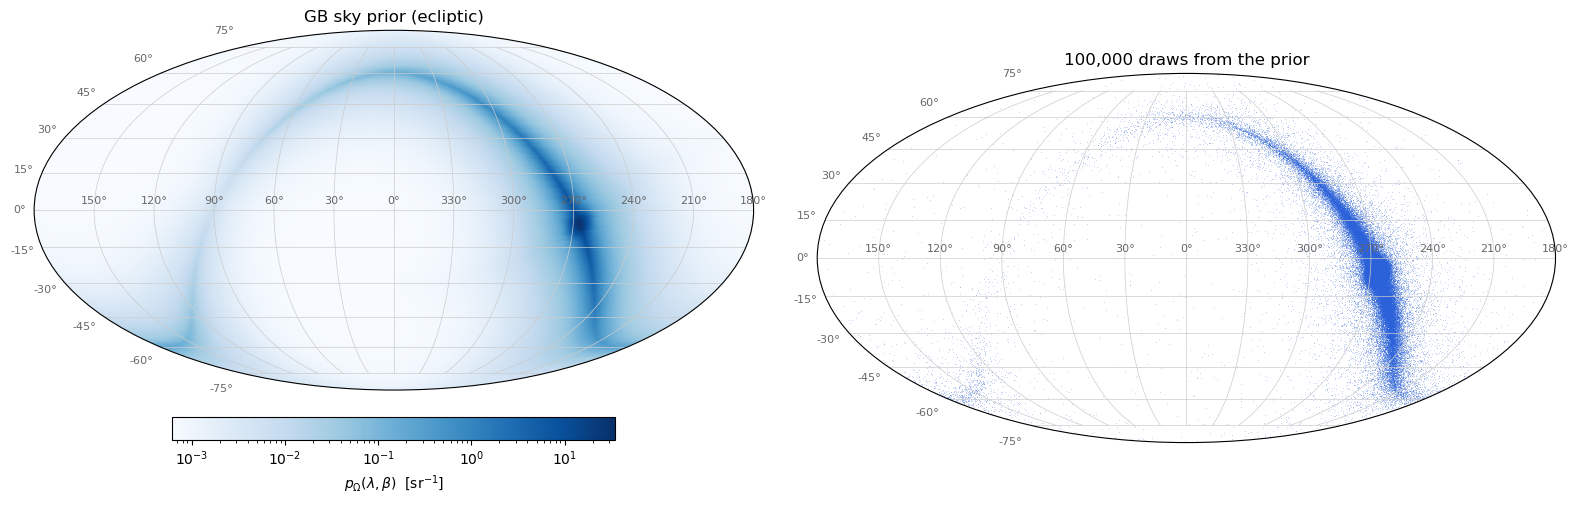

In [4]:
def to_moll(lam):
    # matplotlib's mollweide wants longitude in [-pi, pi]; flip so lambda increases to the left
    return -(np.mod(lam + np.pi, 2 * np.pi) - np.pi)


fig, axes = plt.subplots(1, 2, figsize=(16, 5), subplot_kw=dict(projection="mollweide"))

# left: the prior density per steradian, p(lambda, beta) / cos(beta)
xe = np.linspace(-np.pi, np.pi, 721)                   # plot-longitude edges
ye = np.linspace(-np.pi / 2, np.pi / 2, 361)
XC, YC = np.meshgrid(0.5 * (xe[1:] + xe[:-1]), 0.5 * (ye[1:] + ye[:-1]))
dens = p_omega(*ecl_to_gal(-XC, YC))                   # plot longitude x <-> lambda = -x
pm = axes[0].pcolormesh(xe, ye, dens, norm=LogNorm(), cmap="Blues", rasterized=True)
fig.colorbar(pm, ax=axes[0], orientation="horizontal", pad=0.06, shrink=0.6,
             label=r"$p_\Omega(\lambda,\beta)$  [sr$^{-1}$]")
axes[0].set_title("GB sky prior (ecliptic)")

# right: draws from the prior
axes[1].scatter(to_moll(lam_s), beta_s, s=0.3, alpha=0.3, color="#2b62d9", lw=0, rasterized=True)
axes[1].set_title(f"{N_DRAW:,} draws from the prior")

xt = np.deg2rad(np.arange(-150, 181, 30))
for ax in axes:
    ax.grid(color="0.8", lw=0.5)
    ax.set_xticks(xt)
    ax.set_xticklabels([f"{np.mod(-d, 360):.0f}°" for d in np.rad2deg(xt)], fontsize=8, color="0.4")
    ax.tick_params(axis="y", labelsize=8, labelcolor="0.4")
plt.tight_layout()
plt.show()